# Posterior parameter recovery

Set `ARTIFACT_DIR`, choose how many recovery cases to run, and draw posterior samples for each case.


In [1]:
import copy
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from tqdm.auto import tqdm

try:
    import pandas as pd
except ModuleNotFoundError:
    pd = None

project_root = Path.cwd()
if not (project_root / "tasks").exists():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

try:
    import scienceplots  # noqa: F401
except ModuleNotFoundError:
    pass
else:
    plt.style.use("science")

from network_creation.model_inversion import (
    decode_discrete_theta_samples,
    load_posterior_artifact,
)
from network_creation.model_inversion.diagnostics import (
    DiagnosticData,
    load_diagnostic_data,
    marginal_sbc_ranks,
    plot_expected_coverage,
)
from network_creation.model_inversion.recovery import (
    observation_from_policy_outputs,
    parameter_recovery_summary,
    plot_parameter_marginals,
    plot_parameter_pairs,
    plot_posterior_ridgelines,
)
from tasks.policies import prepare_policy_run
import inspect
from tqdm.auto import tqdm

## Config


In [2]:
ARTIFACT_DIR = "mnpe-20260521T143538Z"

N_RECOVERY_CASES = 1
N_POSTERIOR_SAMPLES_PER_CASE = 1024
SEED = 42
DEVICE = "cpu"
MAX_SAMPLING_TIME_SECONDS = 300

## Helpers


In [3]:
def resolve_existing_path(raw_path):
    path = Path(raw_path).expanduser()
    if path.is_absolute():
        return path.resolve()
    candidates = [
        project_root / path,
        project_root / "artifacts" / "model_inversion" / path,
        path,
    ]
    if "artifact_dir" in globals():
        candidates.append(artifact_dir / path)
    return next(
        (candidate.resolve() for candidate in candidates if candidate.exists()),
        (project_root / path).resolve(),
    )


def n_agents_values(raw_n_agents):
    if isinstance(raw_n_agents, dict):
        if raw_n_agents.get("kind") != "sampled_discrete_range":
            raise ValueError(f"Unsupported n_agents spec: {raw_n_agents}")
        return list(
            range(
                int(raw_n_agents["min"]),
                int(raw_n_agents["max"]) + 1,
                int(raw_n_agents.get("step", 1)),
            )
        )
    if isinstance(raw_n_agents, list):
        return [int(value) for value in raw_n_agents]
    return [int(raw_n_agents)]


def make_recovery_config(source_config, seed, n_episodes=None):
    config = copy.deepcopy(source_config)
    rng = np.random.default_rng(seed)
    population = config["population"]
    proportions = population["policy_proportions"]

    population["n_agents"] = int(rng.choice(n_agents_values(population["n_agents"])))
    proportions["values"] = [float(rng.choice(proportions["values"]))]
    config["sampling"]["log2_budget"] = 0
    config["sampling"]["seed"] = int(seed)
    config["simulator"]["seed"] = (
        int(source_config["simulator"]["seed"]) + 10000 + int(seed)
    )
    if n_episodes is not None:
        config["simulator"]["n_episodes"] = int(n_episodes)

    return config, {
        "seed": int(seed),
        "n_agents": population["n_agents"],
        "policy_proportion": proportions["values"][0],
        "simulator_seed": config["simulator"]["seed"],
        "n_episodes": config["simulator"]["n_episodes"],
    }


def true_theta_from_prepared(prepared, theta_order):
    input_coordinates = np.asarray(prepared.result_arrays["input_coordinates"])
    coordinates = tuple(int(value) for value in input_coordinates[0])
    names = list(prepared.result_attrs["parameter_names"])
    values = np.asarray(prepared.result_arrays["parameters"])[coordinates]
    by_name = {name: float(value) for name, value in zip(names, values, strict=True)}
    by_name["n_agents"] = float(
        np.asarray(prepared.result_arrays["n_agents"])[coordinates[0]]
    )
    missing = [name for name in theta_order if name not in by_name]
    if missing:
        raise KeyError(f"Theta names missing from recovery config: {missing}")
    return np.asarray([by_name[name] for name in theta_order], dtype=np.float32)


def sample_posterior(artifact, x, n_samples, seed, progress=None):
    chunk_size = 128
    chunks = []
    remaining = int(n_samples)
    chunk_index = 0
    while remaining > 0:
        this_n = min(chunk_size, remaining)
        samples, _ = artifact.sample(
            x,
            num_samples=this_n,
            seed=int(seed) + chunk_index,
            device=DEVICE,
            max_sampling_time=MAX_SAMPLING_TIME_SECONDS,
            return_partial_on_timeout=True,
            show_progress_bars=False,
            max_sampling_batch_size=max(1, 100_000 // this_n),
        )
        if samples.shape[0] == 0:
            raise RuntimeError(
                "Posterior sampling returned no samples before max_sampling_time."
            )
        chunks.append(samples)
        remaining -= int(samples.shape[0])
        if progress is not None:
            progress.update(int(samples.shape[0]))
        chunk_index += 1
    return np.concatenate(chunks, axis=0)[:n_samples].astype(np.float32)

## Load Artifact


In [4]:
artifact_dir = resolve_existing_path(ARTIFACT_DIR)
artifact = load_posterior_artifact(artifact_dir)
metadata = artifact.metadata
dataset_metadata = metadata["dataset"]
prior_samples = artifact.prior_samples
diagnostic_data = load_diagnostic_data(artifact)
theta_names = list(artifact.theta_order)

source_config_path = resolve_existing_path(dataset_metadata["config_path"])
source_config = json.loads(source_config_path.read_text(encoding="utf-8"))

display(
    {
        "artifact_dir": (
            str(artifact_dir.relative_to(project_root))
            if artifact_dir.is_relative_to(project_root)
            else str(artifact_dir)
        ),
        "posterior_type": type(artifact.posterior).__name__,
        "theta_order": theta_names,
        "x_shape": tuple(dataset_metadata["x_event_shape"]),
        "stored_prior_samples": int(prior_samples.shape[0]),
    }
)

{'artifact_dir': 'artifacts/model_inversion/mnpe-20260521T143538Z',
 'posterior_type': 'DirectPosterior',
 'theta_order': ['outside_optimism', 'exploration', 'visibility_distance'],
 'x_shape': (81, 4),
 'stored_prior_samples': 4096}

## Learning Curve


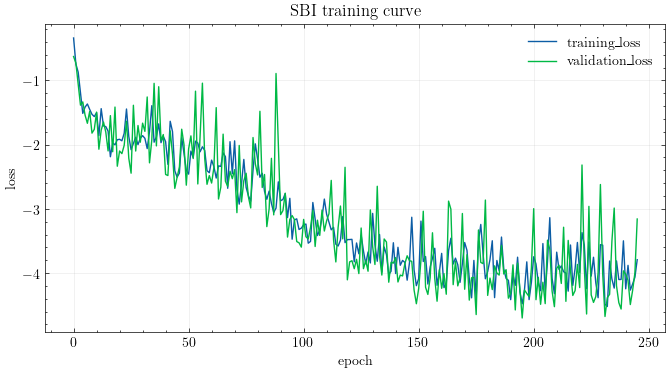

,tag,n_points,first,last,min,max
0,training_loss,246,-0.338072,-3.792281,-4.521380,-0.338072
1,validation_loss,246,-0.626996,-3.158459,-4.700485,-0.626996
2,epochs_trained,1,246.000000,246.000000,246.000000,246.000000
3,best_validation_loss,1,-4.700485,-4.700485,-4.700485,-4.700485


In [5]:
try:
    from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
except ModuleNotFoundError:
    EventAccumulator = None

learning_scalars = {}
if EventAccumulator is not None and artifact.tensorboard_log_dir.is_dir():
    accumulator = EventAccumulator(str(artifact.tensorboard_log_dir))
    accumulator.Reload()
    available_tags = set(accumulator.Tags().get("scalars", []))
    for tag in (
        "training_loss",
        "validation_loss",
        "epochs_trained",
        "best_validation_loss",
    ):
        if tag in available_tags:
            events = accumulator.Scalars(tag)
            learning_scalars[tag] = {
                "step": np.asarray([event.step for event in events]),
                "value": np.asarray([event.value for event in events]),
            }

curve_tags = [
    tag for tag in ("training_loss", "validation_loss") if tag in learning_scalars
]
if curve_tags:
    fig, ax = plt.subplots(figsize=(8, 4))
    for tag in curve_tags:
        curve = learning_scalars[tag]
        ax.plot(curve["step"], curve["value"], label=tag)
    ax.set_xlabel("epoch")
    ax.set_ylabel("loss")
    ax.set_title("SBI training curve")
    ax.legend(frameon=False)
    ax.grid(alpha=0.25)
    plt.show()

if learning_scalars:
    rows = [
        {
            "tag": tag,
            "n_points": len(curve["value"]),
            "first": float(curve["value"][0]),
            "last": float(curve["value"][-1]),
            "min": float(np.min(curve["value"])),
            "max": float(np.max(curve["value"])),
        }
        for tag, curve in learning_scalars.items()
        if len(curve["value"])
    ]
    display(pd.DataFrame(rows) if pd is not None else rows)
elif EventAccumulator is None:
    display(
        Markdown("TensorBoard is not installed, so no learning curve can be loaded.")
    )
else:
    display(
        Markdown(
            f"No TensorBoard scalar logs found under `{artifact.tensorboard_log_dir}`."
        )
    )

## Generate Recovery Cases


In [6]:
recovery_cases = []
expected_x_shape = tuple(dataset_metadata["x_event_shape"])

for case_index in range(N_RECOVERY_CASES):
    case_seed = SEED + case_index
    recovery_config, choices = make_recovery_config(source_config, case_seed)
    prepared = prepare_policy_run(recovery_config)
    outputs = prepared.run(0)
    recovery_x = observation_from_policy_outputs(
        outputs,
        artifact,
        n_agents=int(choices["n_agents"]),
        n_actors=int(recovery_config["simulator"]["actor_scheduler"]["n_actors"]),
    )
    if tuple(recovery_x.shape) != expected_x_shape:
        raise ValueError(
            f"recovery_x shape {tuple(recovery_x.shape)} does not match expected shape {expected_x_shape}"
        )

    recovery_cases.append(
        {
            "case": case_index,
            "choices": choices,
            "true_theta": true_theta_from_prepared(prepared, theta_names),
            "x": recovery_x,
        }
    )

choice_rows = [{"case": case["case"], **case["choices"]} for case in recovery_cases]
display(pd.DataFrame(choice_rows) if pd is not None else choice_rows)

,case,seed,n_agents,policy_proportion,simulator_seed,n_episodes
0,0,42,10,1.0,10053,16


## Sample Posterior


In [7]:
posterior_samples = np.asarray(
    [
        sample_posterior(
            artifact,
            case["x"],
            n_samples=N_POSTERIOR_SAMPLES_PER_CASE,
            seed=SEED + int(case["case"]),
        )
        for case in recovery_cases
    ],
    dtype=np.float32,
)

display(
    {
        "requested_shape": (
            N_RECOVERY_CASES,
            N_POSTERIOR_SAMPLES_PER_CASE,
            len(theta_names),
        ),
        "returned_shape": tuple(posterior_samples.shape),
        "requested_posterior_samples_per_case": N_POSTERIOR_SAMPLES_PER_CASE,
        "returned_posterior_samples_per_case": [
            int(samples.shape[0]) for samples in posterior_samples
        ],
    }
)

/home/hdahmou/Network_creation/.venv/lib/python3.13/site-packages/nflows/transforms/lu.py:80: UserWarning: torch.triangular_solve is deprecated in favor of torch.linalg.solve_triangularand will be removed in a future PyTorch release.
torch.linalg.solve_triangular has its arguments reversed and does not return a copy of one of the inputs.
X = torch.triangular_solve(B, A).solution
should be replaced with
X = torch.linalg.solve_triangular(A, B). (Triggered internally at ../aten/src/ATen/native/BatchLinearAlgebra.cpp:2190.)
  outputs, _ = torch.triangular_solve(


{'requested_shape': (1, 1024, 3),
 'returned_shape': (1, 1024, 3),
 'requested_posterior_samples_per_case': 1024,
 'returned_posterior_samples_per_case': [1024]}

## Recovery Summary


In [8]:
summary_rows = []
for case in recovery_cases:
    rows = parameter_recovery_summary(
        artifact,
        true_theta=case["true_theta"],
        posterior_samples=posterior_samples[int(case["case"])],
    )
    summary_rows.extend({"case": case["case"], **row} for row in rows)

display(pd.DataFrame(summary_rows) if pd is not None else summary_rows)

,case,theta,type,true,posterior_mean,posterior_median,q05,q95,abs_error_mean,covered_by_90_interval,posterior_mode,posterior_p_true
0,0,outside_optimism,continuous,0.205198,0.188679,0.188591,0.18312,0.194746,0.016519,False,NaN,NaN
1,0,exploration,continuous,0.066285,0.060082,0.059923,0.05620,0.064501,0.006203,False,NaN,NaN
2,0,visibility_distance,categorical,5.000000,NaN,NaN,NaN,NaN,NaN,NaN,5.0,0.442383


## Plots


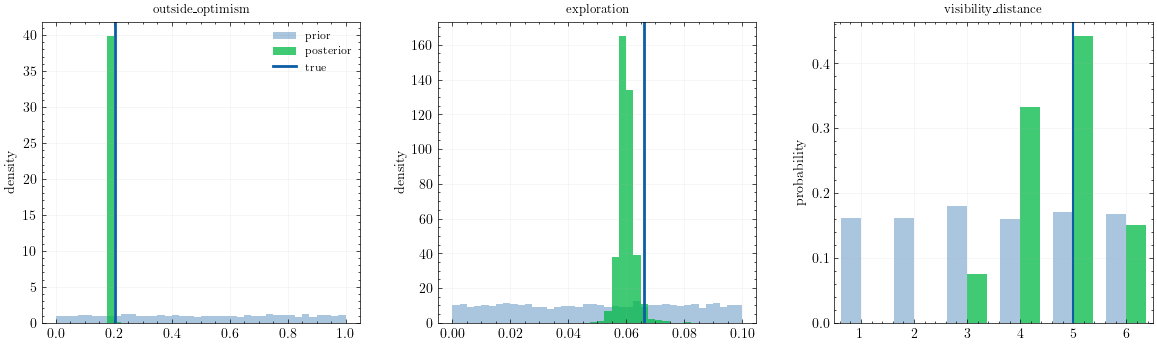

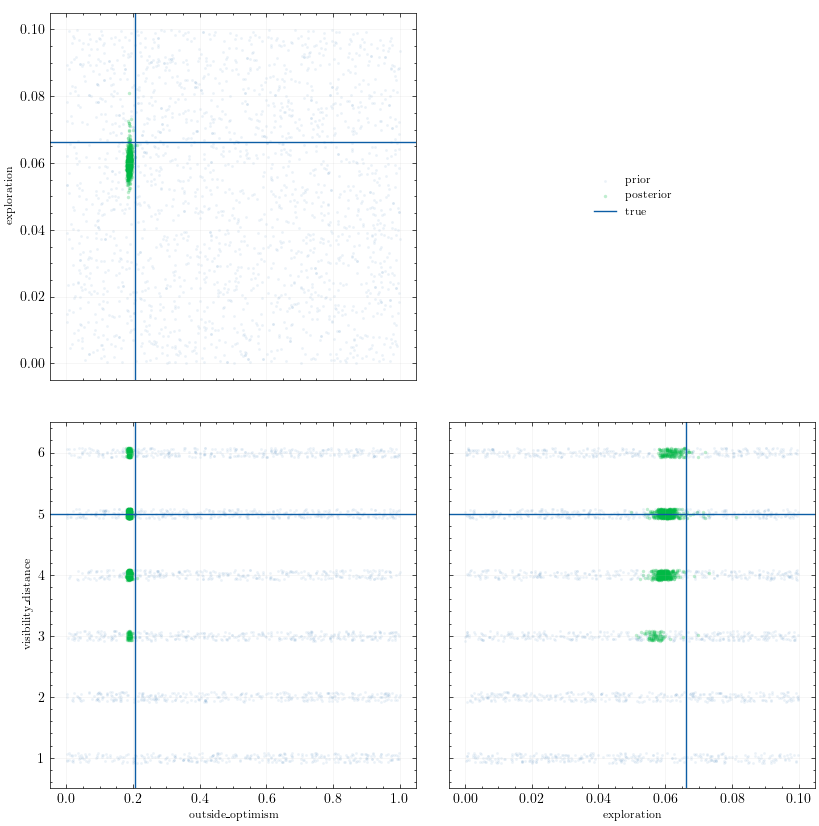

In [9]:
CASE_TO_PLOT = 0

case = recovery_cases[CASE_TO_PLOT]
case_samples = posterior_samples[CASE_TO_PLOT]
true_theta = case["true_theta"]

fig = plot_parameter_marginals(
    artifact,
    prior_samples=prior_samples,
    posterior_samples=case_samples,
    true_theta=true_theta,
)
fig.set_size_inches(4 * len(theta_names), 4)
plt.show()

if len(theta_names) < 2:
    display(Markdown("Pair plot requires at least two theta dimensions."))
else:
    fig = plot_parameter_pairs(
        artifact,
        prior_samples=prior_samples,
        posterior_samples=case_samples,
        true_theta=true_theta,
        seed=SEED,
    )
    fig.set_size_inches(3 * len(theta_names), 3 * len(theta_names))
    plt.show()

## Optional Diagnostics


In [11]:
N_DIAGNOSTIC_CASES = 100
N_DIAGNOSTIC_POSTERIOR_SAMPLES_PER_CASE = 2**8

rng = np.random.default_rng(SEED)
requested_cases = N_DIAGNOSTIC_CASES
n_cases = min(N_DIAGNOSTIC_CASES, diagnostic_data.theta.shape[0])
diagnostic_indices = np.sort(
    rng.choice(diagnostic_data.theta.shape[0], size=n_cases, replace=False)
)
diagnostic_subset = DiagnosticData(
    theta=decode_discrete_theta_samples(
        diagnostic_data.theta[diagnostic_indices], metadata
    ),
    x=diagnostic_data.x[diagnostic_indices],
    source_sample=diagnostic_data.source_sample[diagnostic_indices],
)
diagnostic_posterior_samples = []
progress_total = n_cases * N_DIAGNOSTIC_POSTERIOR_SAMPLES_PER_CASE
sample_posterior_accepts_progress = (
    "progress" in inspect.signature(sample_posterior).parameters
)
with tqdm(
    total=progress_total, desc="Sampling diagnostic posteriors", unit="sample"
) as progress:
    for offset, x in enumerate(diagnostic_subset.x):
        progress.set_postfix(case=f"{offset + 1}/{n_cases}")
        sample_kwargs = {
            "n_samples": N_DIAGNOSTIC_POSTERIOR_SAMPLES_PER_CASE,
            "seed": SEED + offset,
        }
        if sample_posterior_accepts_progress:
            sample_kwargs["progress"] = progress
        samples = sample_posterior(artifact, x, **sample_kwargs)
        if not sample_posterior_accepts_progress:
            progress.update(int(samples.shape[0]))
        diagnostic_posterior_samples.append(samples)
diagnostic_posterior_samples = np.asarray(
    diagnostic_posterior_samples, dtype=np.float32
)

display(
    {
        "diagnostic_cases": int(diagnostic_posterior_samples.shape[0]),
        "posterior_samples_per_case": int(diagnostic_posterior_samples.shape[1]),
        "theta_dim": int(diagnostic_posterior_samples.shape[2]),
    }
)

Sampling diagnostic posteriors:   0%|          | 0/25600 [00:00<?, ?sample/s]

{'diagnostic_cases': 100, 'posterior_samples_per_case': 256, 'theta_dim': 3}

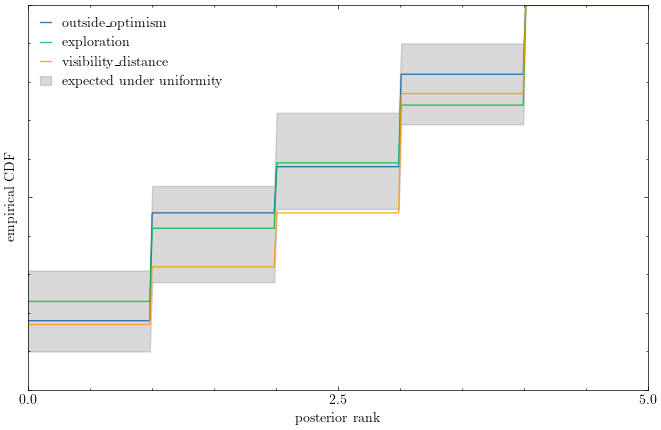

In [12]:
ranks = marginal_sbc_ranks(
    artifact,
    diagnostic_posterior_samples,
    diagnostic_subset.theta,
    seed=SEED,
)
coverage = {
    "ranks": ranks,
    "dap_samples": diagnostic_posterior_samples[:, 0, :],
    "num_posterior_samples": N_DIAGNOSTIC_POSTERIOR_SAMPLES_PER_CASE,
    "n_diagnostic_simulations": int(diagnostic_subset.theta.shape[0]),
}
fig, ax = plot_expected_coverage(artifact, coverage)
plt.show()

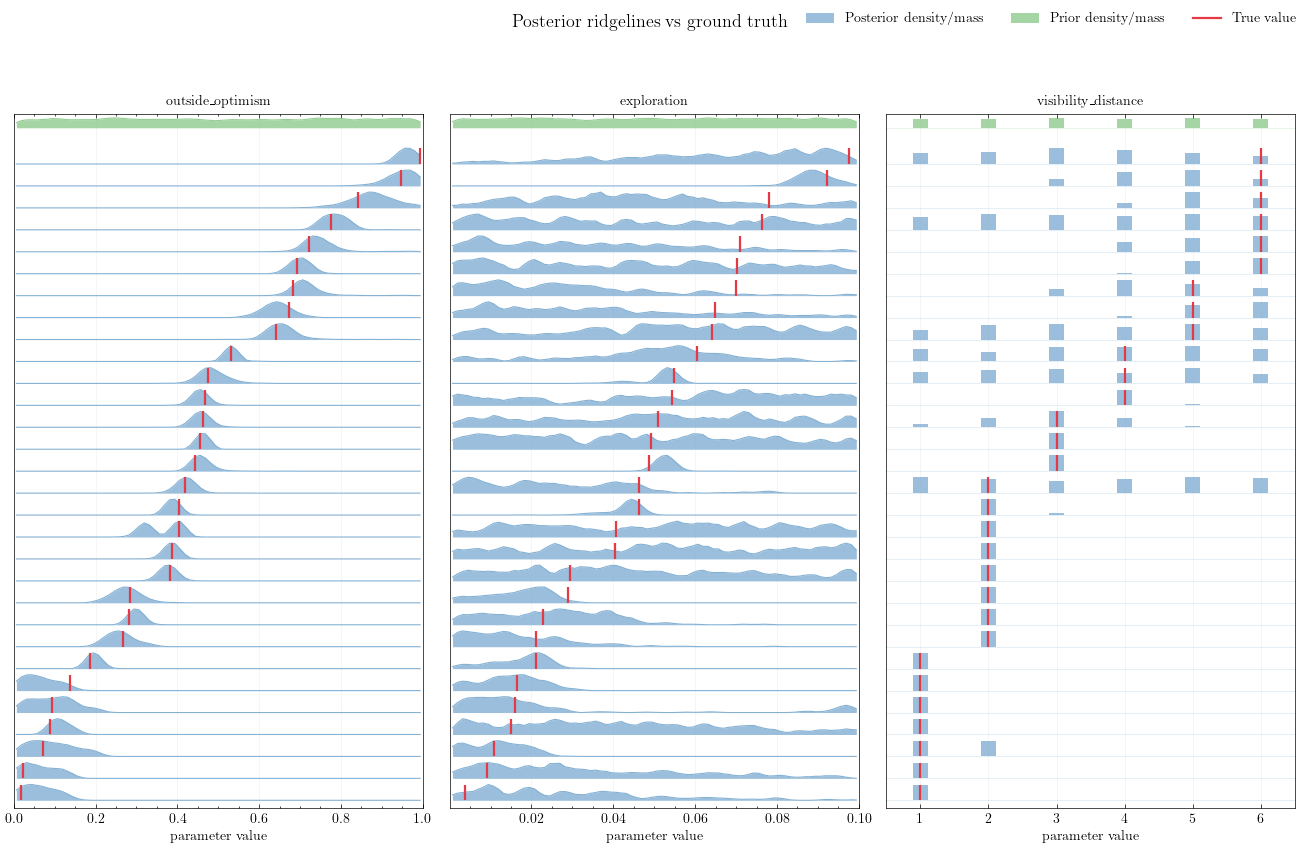

In [13]:
ridgeline_count = 30
fig = plot_posterior_ridgelines(
    artifact,
    prior_samples=prior_samples,
    posterior_samples=diagnostic_posterior_samples[:ridgeline_count],
    true_theta=diagnostic_subset.theta[:ridgeline_count],
)
plt.show()